# 01 · Data pipeline and DL dataset
Rubric items: *DL Dataset & Regularization*, *Technical Validation*

**Goal.** Turn the raw M5 files into a clean panel that every model (Kalman, LightGBM, DeepAR, hybrid) shares.

Rules we follow (from the project brief):
1. **Complete date index** per SKU — every SKU has a row for every day.
2. **Mark, don't impute** stockouts — a flag, never a made-up sales number.
3. **No peeking ahead** — every feature at day *t* uses only information known at *t*.
4. **Encode the calendar** (day of week, month, SNAP, events) and price.
5. **Split by forecast origin** (rolling origins), not randomly.

In [1]:
%run ./00_common.ipynb

common loaded | ROOT=/Users/Harsh/Downloads/inventory-demand-forecasting 2 | device=cpu | H=28, C=56, origins={'O1': 915, 'O2': 943, 'O3': 971}


## 1. Load raw M5 data and select the SKU subset
We use one store (`CA_1`) and three departments with very different demand behaviour:
`FOODS_3` (high volume), `HOUSEHOLD_1` (medium) and `HOBBIES_1` (sparse / intermittent).
100 SKUs are drawn at random from each department (seed 42) → **300 series**.

In [2]:
sales = pd.read_csv(RAW / "sales_train_evaluation.csv")
calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
prices = pd.read_csv(RAW / "sell_prices.csv")

sales = sales[(sales.store_id == CFG["store"]) & (sales.dept_id.isin(CFG["depts"]))]
rng = np.random.default_rng(CFG["seed"])
picked = []
for dept in CFG["depts"]:
    ids = sales.loc[sales.dept_id == dept, "id"].values
    picked += list(rng.choice(ids, CFG["items_per_dept"], replace=False))
sales = sales[sales.id.isin(picked)].sort_values(["dept_id", "item_id"]).reset_index(drop=True)
print(sales.shape, sales.dept_id.value_counts().to_dict())

(300, 1947) {'FOODS_3': 100, 'HOBBIES_1': 100, 'HOUSEHOLD_1': 100}


## 2. Long format with a complete date index
We keep the last 1000 days (`d_942 … d_1941`, Aug 2013 – May 2016). We then re-index on the full
(SKU × day) grid and **assert** that nothing is missing.

In [3]:
day_cols = [f"d_{i}" for i in range(CFG["start_d"], CFG["end_d"] + 1)]
long = sales.melt(id_vars=["id", "item_id", "dept_id"], value_vars=day_cols, var_name="d", value_name="sales")
long["dnum"] = long["d"].str[2:].astype(int)
long["t"] = long["dnum"] - CFG["start_d"]

cal = calendar.copy()
cal["dnum"] = cal["d"].str[2:].astype(int)
cal = cal[(cal.dnum >= CFG["start_d"]) & (cal.dnum <= CFG["end_d"])].reset_index(drop=True)
long = long.merge(cal[["dnum", "date", "wm_yr_wk"]], on="dnum", how="left")
long = long.merge(prices[prices.store_id == CFG["store"]][["item_id", "wm_yr_wk", "sell_price"]],
                  on=["item_id", "wm_yr_wk"], how="left")

full_index = pd.MultiIndex.from_product([sales.id.values, np.arange(len(day_cols))], names=["id", "t"])
long = long.set_index(["id", "t"]).reindex(full_index).reset_index()
assert long["sales"].notna().all(), "missing (SKU, day) rows!"
print("rows:", len(long), "=", len(sales), "SKUs x", len(day_cols), "days  -> complete index OK")

rows: 300000 = 300 SKUs x 1000 days  -> complete index OK


## 3. Availability: not launched / not listed / store closed
* An item **without a price** in a week is *not on the shelf* (typically: not launched yet). Its zeros are not
  demand, so we set sales to **NaN** (missing), not 0.
* The store is **closed on Christmas** (all items sell 0) → also NaN.

In [4]:
N, T = len(sales), len(day_cols)
Y = long["sales"].values.reshape(N, T).astype(np.float32)
PRICE = long["sell_price"].values.reshape(N, T).astype(np.float32)
LISTED = (~np.isnan(PRICE)).astype(np.float32)
dates = cal["date"].values
closed = (cal["date"].dt.month == 12).values & (cal["date"].dt.day == 25).values

Y[LISTED == 0] = np.nan
Y[:, closed] = np.nan
launch_t = np.argmax(LISTED > 0, axis=1)
print("store-closed days:", closed.sum(), "| SKUs launched inside the window:", (launch_t > 0).sum())

store-closed days: 3 | SKUs launched inside the window: 52


## 4. Causal stockout detection (mark, don't impute)
M5 has no inventory data, so we *infer* probable stockouts. Under a Poisson demand model with recent rate λ
(mean of the 56 days before the zero-run started), a run of *k* consecutive zeros has probability $e^{-\lambda k}$.
When this drops below **0.1 %** we flag the day as a *probable stockout*.

The flag at day *t* only uses sales up to *t* → it is **causal**, so it can be used as a model input
without leaking the future. Flagged days are **excluded from the training loss** and the Kalman update,
and reported separately in evaluation. Their sales value stays as recorded (0).

In [5]:
THRESH = np.log(1000)          # e^{-lambda k} < 1e-3  <=>  lambda * k > 6.91


def flag_stockouts(y, lookback=56):
    flags = np.zeros(len(y), dtype=np.int8)
    run_start, lam = None, 0.0
    for t in range(len(y)):
        if np.isnan(y[t]) or y[t] > 0:
            run_start = None
            continue
        if run_start is None:                       # a new zero-run starts: fix lambda from the past
            run_start = t
            past = y[max(0, t - lookback):t]
            past = past[~np.isnan(past) & (flags[max(0, t - lookback):t] == 0)]
            lam = past.mean() if len(past) >= 14 else 0.0
        k = t - run_start + 1
        if lam * k > THRESH:
            flags[t] = 1
    return flags


STOCK = np.stack([flag_stockouts(Y[i]) for i in range(N)])
print(f"flagged stockout days: {STOCK.sum()} ({100*STOCK.sum()/np.sum(~np.isnan(Y)):.2f}% of observed days)")
print("SKUs with at least one flagged day:", (STOCK.sum(1) > 0).sum())

flagged stockout days: 24539 (8.61% of observed days)
SKUs with at least one flagged day: 272


**Leakage test.** Re-computing the flags on a series cut at day *t* must give the same flags up to *t*.

In [6]:
for i in rng.choice(N, 20, replace=False):
    cut = int(rng.integers(200, T))
    assert np.array_equal(flag_stockouts(Y[i, :cut]), STOCK[i, :cut])
print("causality test passed: flags never depend on future sales")

causality test passed: flags never depend on future sales


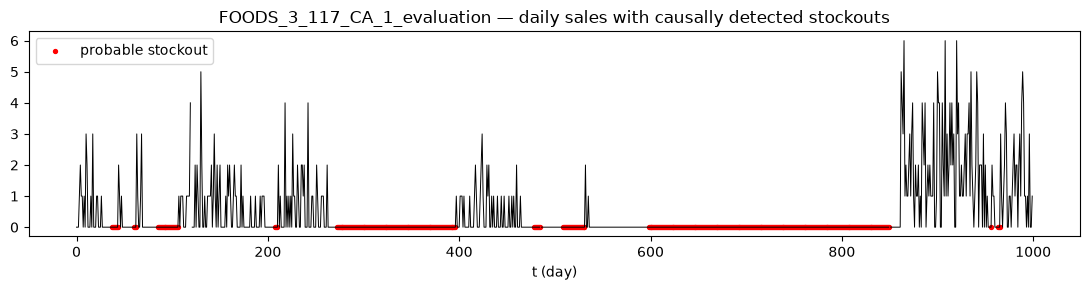

In [7]:
i_ex = int(np.argmax(STOCK[:100].sum(1)))   # a FOODS SKU with many flagged days
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(Y[i_ex], lw=0.7, color="black")
ax.scatter(np.where(STOCK[i_ex])[0], np.zeros(STOCK[i_ex].sum()), color="red", s=8, label="probable stockout")
ax.set_title(f"{sales.id[i_ex]} — daily sales with causally detected stockouts"); ax.legend(); ax.set_xlabel("t (day)")
plt.tight_layout(); plt.savefig(FIG / "01_stockout_example.png", dpi=150); plt.show()

## 5. Known-in-advance covariates (calendar + price)
All of these are known for future days at forecast time, so they may be used in the 28-day prediction range.

| feature | encoding |
|---|---|
| day of week | one-hot (7) |
| month | sin / cos (2) — cyclic, Dec is next to Jan |
| SNAP day (CA) | 0/1 |
| event day | 0/1 (any of the 4 M5 event types) |
| relative price | log(price / item median price in training) |
| listed | 0/1 |
| age | log(1 + days since launch) / log(1000) |

In [8]:
dow = cal["date"].dt.dayofweek.values                  # 0 = Monday
month = cal["date"].dt.month.values
cal_feats = np.column_stack([
    np.eye(7)[dow],
    np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12),
    cal["snap_CA"].values,
    cal["event_name_1"].notna().values.astype(float),
]).astype(np.float32)                                   # (T, 11)

fit_end = ORIGINS["O1"] - H                             # last day of the earliest training period
med_price = np.nanmedian(np.where(np.arange(T) <= fit_end, PRICE, np.nan), axis=1)
med_price = np.where(np.isnan(med_price), np.nanmedian(PRICE, axis=1), med_price)
rel_price = np.nan_to_num(np.log(PRICE / med_price[:, None]))
age = np.clip(np.arange(T)[None, :] - launch_t[:, None], 0, None)
age_feat = np.log1p(age) / np.log(1000) * LISTED

X = np.concatenate([
    np.broadcast_to(cal_feats, (N, T, cal_feats.shape[1])),
    rel_price[..., None], LISTED[..., None], age_feat[..., None],
], axis=-1).astype(np.float32)
COV_NAMES = [f"dow_{d}" for d in range(7)] + ["month_sin", "month_cos", "snap", "event", "rel_price", "listed", "age"]
print("X shape:", X.shape)

X shape: (300, 1000, 14)


## 6. Demand segments (Syntetos–Boylan) and cold-start items
Computed **on the training period only** (up to the first validation cut-off):
* **ADI** = average interval between non-zero sales, **CV²** = squared coefficient of variation of non-zero sizes.
* smooth (ADI<1.32, CV²<0.49), erratic (ADI<1.32, CV²≥0.49), intermittent (ADI≥1.32, CV²<0.49), lumpy (both high).
* **new item** = fewer than 365 days of history before the first test origin.

In [9]:
def adi_cv2(y):
    y = y[~np.isnan(y)]
    nz = y[y > 0]
    if len(nz) < 2:
        return np.inf, np.nan
    return len(y) / len(nz), (nz.std() / nz.mean()) ** 2


rows = []
for i in range(N):
    adi, cv2 = adi_cv2(Y[i, :fit_end + 1])
    if adi < 1.32:
        seg = "smooth" if cv2 < 0.49 else "erratic"
    else:
        seg = "intermittent" if (np.isnan(cv2) or cv2 < 0.49) else "lumpy"
    rows.append(dict(adi=adi, cv2=cv2, segment=seg))
meta = sales[["id", "item_id", "dept_id"]].copy()
meta = pd.concat([meta, pd.DataFrame(rows)], axis=1)
meta["item_idx"] = np.arange(N)
meta["dept_idx"] = meta["dept_id"].map({d: k for k, d in enumerate(CFG["depts"])})
meta["launch_t"] = launch_t
meta["history_days"] = ORIGINS["O1"] - launch_t
meta["is_new"] = meta["history_days"] < 365
meta["mean_sales"] = np.nanmean(Y[:, :fit_end + 1], axis=1)
meta["zero_share"] = np.nanmean(Y[:, :fit_end + 1] == 0, axis=1)
print(pd.crosstab(meta.dept_id, meta.segment))
print("new items:", meta.is_new.sum())

segment      erratic  intermittent  lumpy  smooth
dept_id                                          
FOODS_3            4            51     28      17
HOBBIES_1          8            75     14       3
HOUSEHOLD_1        1            75      8      16
new items: 4


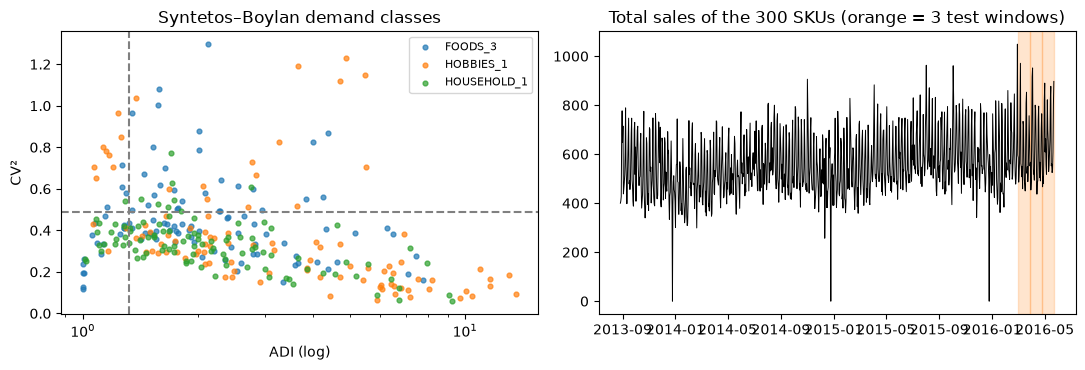

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for d, g in meta.groupby("dept_id"):
    axes[0].scatter(np.clip(g.adi, 1, 20), g.cv2, s=12, label=d, alpha=0.7)
axes[0].axvline(1.32, ls="--", c="grey"); axes[0].axhline(0.49, ls="--", c="grey")
axes[0].set_xscale("log"); axes[0].set_xlabel("ADI (log)"); axes[0].set_ylabel("CV²")
axes[0].set_title("Syntetos–Boylan demand classes"); axes[0].legend(fontsize=8)
tot = np.nansum(Y, axis=0)
axes[1].plot(dates, tot, lw=0.7, color="black")
for k, o in ORIGINS.items():
    axes[1].axvspan(dates[o + 1], dates[min(o + H, T - 1)], alpha=0.2, color="C1")
axes[1].set_title("Total sales of the 300 SKUs (orange = 3 test windows)")
plt.tight_layout(); plt.savefig(FIG / "01_segments_and_total.png", dpi=150); plt.show()

## 7. Rolling-origin split
Each origin *o* uses: **train** windows ending ≤ *o−28*, **validation** (early stopping) = *(o−28, o]*,
**test** = *(o, o+28]*. Models are re-trained for each origin.

In [11]:
split_rows = []
for k, o in ORIGINS.items():
    split_rows.append(dict(origin=k, train_end=str(dates[o - H])[:10], val=f"{str(dates[o-H+1])[:10]} .. {str(dates[o])[:10]}",
                           test=f"{str(dates[o+1])[:10]} .. {str(dates[o+H])[:10]}"))
splits = pd.DataFrame(split_rows); splits

,origin,train_end,val,test
0,O1,2016-01-31,2016-02-01 .. 2016-02-28,2016-02-29 .. 2016-03-27
1,O2,2016-02-28,2016-02-29 .. 2016-03-27,2016-03-28 .. 2016-04-24
2,O3,2016-03-27,2016-03-28 .. 2016-04-24,2016-04-25 .. 2016-05-22


## 8. Save the panel

In [12]:
np.savez_compressed(PROC / "panel.npz", Y=Y, LISTED=LISTED, STOCK=STOCK, X=X, PRICE=PRICE,
                    dow=dow, dates=dates.astype("datetime64[D]").astype(str), cov_names=np.array(COV_NAMES))
meta.to_csv(PROC / "series_meta.csv", index=False)
splits.to_csv(TAB / "rolling_origins.csv", index=False)
print("saved", PROC / "panel.npz")

saved /Users/Harsh/Downloads/inventory-demand-forecasting 2/data/processed/panel.npz


## 9. The DL dataset: how a training window looks
The functions `make_batch` / `sample_train_windows` (Section B of `00_common`) turn the panel into tensors.
Below we check the shapes and three properties that matter for **regularisation and validity**:
1. **Scaling** by ν = 1 + mean(context) makes a 0.2 units/day HOBBIES item and a 40 units/day FOODS item look alike
   to the network → one set of weights can be shared (*global model*).
2. **Loss mask** removes not-on-sale and stockout days from the likelihood.
3. **No look-ahead**: the input channel `y_prev` at position *j* equals the target at *j−1*.

In [13]:
P = load_panel()
mcfg = dict(MODEL_CFG)
rng = np.random.default_rng(0)
sidx, t0 = sample_train_windows(P, np.arange(P["N"]), ORIGINS["O1"] - H, 2, rng)
b = make_batch(P, sidx[:8], t0[:8], mcfg)
print({k: tuple(v.shape) for k, v in b.items() if torch.is_tensor(v)})
assert torch.allclose(b["dyn"][:, 1:, 0] * b["nu"][:, None], b["y"][:, :-1] * (b["dyn"][:, 1:, 1] > 0))
assert (t0 + H <= ORIGINS["O1"] - H).all()
print("no-look-ahead and split checks passed")
print("scale nu (first 8 windows):", np.round(b["nu"].numpy(), 2))
print("share of masked target positions:", 1 - b["mask"].mean().item())

{'dyn': (8, 84, 17), 'y': (8, 84), 'mask': (8, 84), 'nu': (8,), 'item': (8,), 'dept': (8,), 'listed': (8, 84)}
no-look-ahead and split checks passed
scale nu (first 8 windows): [2.07 2.18 1.5  1.62 6.27 7.46 1.79 2.05]
share of masked target positions: 0.03720235824584961


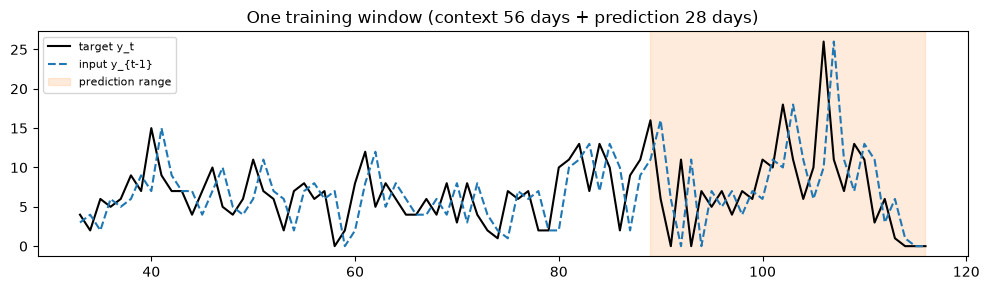

In [14]:
fig, ax = plt.subplots(figsize=(10, 3))
j = int(np.argmax(b["nu"].numpy()))
tt = window_index(t0[j:j+1])[0]
ax.plot(tt, b["y"][j], label="target y_t", color="black")
ax.plot(tt, b["dyn"][j, :, 0] * b["nu"][j], label="input y_{t-1}", ls="--")
ax.axvspan(tt[C], tt[-1], alpha=0.15, color="C1", label="prediction range")
ax.set_title("One training window (context 56 days + prediction 28 days)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "01_training_window.png", dpi=150); plt.show()

**Summary.** 300 SKUs × 1000 days, complete index, causal stockout flags, 14 known covariates,
Syntetos–Boylan segments, and a window sampler that is leak-free. All downstream notebooks read these files.